# Explore the Data

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import io
from pathlib import Path
import requests
from scipy import stats

Before exploration is to begin, we need to make sure the data is clean and ready for analysis. This involves checking for missing values, duplicates, and ensuring that the data types are appropriate for the analysis we plan to conduct.

## Daily Farm Weather (`weather.csv`)

**Records:** 4,338 daily rows (Jan 1 – Mar 1, 1947–2026)
**Granularity:** Daily observations

| Raw Column | Data Type | Physical Units | Missing Values (N=4,338) | Noise & Data Quality Profile | Summary Metrics [Min, Median, Max] |
|---|---|---|---|---|---|
| `date` | datetime64 | YYYY-MM-DD | 0 (0.0%) | Primary daily temporal index. | [1947-01-01, 1986-08-01, 2026-03-01] |
| `max_temp` | float64 | °F | 89 (2.1%) | Station gaps marked as `M`. | [-6.0, 37.0, 78.0] |
| `min_temp` | float64 | °F | 83 (1.9%) | Station gaps marked as `M`. | [-26.0, 21.0, 55.0] |
| `avg_temp` | float64 | °F | 104 (2.4%) | Imputed via (`max_temp` + `min_temp`) / 2 when missing. | [-15.0, 29.5, 61.0] |
| `precipitation` | float64 | Inches | 16 (0.4%) | Trace precipitation (`T`) converted to 0.0. | [0.00, 0.00, 2.56] |
| `snowfall` | float64 | Inches | 44 (1.0%) | Trace snowfall (`T`) converted to 0.0. | [0.00, 0.00, 21.0] |
| `snowdepth` | float64 | Inches | 75 (1.7%) | Ground snowpack level; high variance. | [0.00, 0.00, 33.0] |

## Daily Farm Soil (`soil.csv`)

**Records:** 4,338 daily rows (Jan 1 – Mar 1, 1947–2026)
**Granularity:** Daily 3-inch depth readings

| Raw Column | Data Type | Physical Units | Missing Values (N=4,338) | Noise & Data Quality Profile | Summary Metrics [Min, Median, Max] |
|---|---|---|---|---|---|
| `day` | datetime64 | YYYY-MM-DD | 0 (0.0%) | Primary soil temporal index. | [1947-01-01, 1986-08-01, 2026-03-01] |
| `mean_soil_temp` | float64 | °C | 0 (0.0%) | Clean sensor readings; hovers near 0°C in winter. | [-13.30, -0.21, 12.70] |
| `min_soil_temp` | float64 | °C | 0 (0.0%) | Daily minimum soil temperature. | [-16.20, -0.40, 11.60] |
| `max_soil_temp` | float64 | °C | 0 (0.0%) | Daily maximum soil temperature. | [-11.10, 0.00, 17.10] |
| `mean_soil_moisture` | float64 | m³/m³ | 0 (0.0%) | Extremely low variance; saturated winter ground. | [0.403, 0.473, 0.516] |
| `min_soil_moisture` | float64 | m³/m³ | 0 (0.0%) | Minimum daily soil moisture content. | [0.397, 0.467, 0.513] |
| `max_soil_moisture` | float64 | m³/m³ | 0 (0.0%) | Maximum daily soil moisture content. | [0.410, 0.477, 0.521] |

## Target Labels & Benchmark Predictions (`early_spring.csv` & `phil_pred.csv`)

**Records:** 72 yearly rows (1947–2026)
**Granularity:** Yearly ground truth and historical calls

| File / Column | Data Type | Physical Units | Missing Values (N=72) | Noise & Data Quality Profile | Summary Metrics [Min, Median, Max] |
|---|---|---|---|---|---|
| `early_spring.csv` / `early_spring` | int64 (binary) | {0, 1} | 0 (0.0%) | Client ground truth label (1 = early spring). | [0.0, 0.0, 1.0] (25.0% base rate) |
| `phil_pred.csv` / `prediction` | int64 (binary) | {0, 1} | 0 (0.0%) | Groundhog call (1 = early spring); high intrinsic noise. | [0.0, 0.0, 1.0] (19.4% positive rate) |

Most of the data is clean and ready for analysis, with only a few missing values in the weather dataset. The most notable feature with missing data is `avg_temp`, with 104 missing values, `max_temp` with 89 missing, `min_temp` with 83 missing, and `snow_depth` with 75 missing. The soil dataset is complete with no missing values. The target labels and benchmark predictions are also complete, allowing for a robust evaluation of model performance.

## 1. Daily Farm Weather Features (`weather.csv`)

* `snowdepth`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Strong inverse correlation with `early_spring` (February max snow depth r = -0.322). Snow cover reflects solar heat and physically insulates topsoil, preventing ground warming prior to May 1.
* `snowfall`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Strong inverse correlation with `early_spring` (February cumulative snowfall r = -0.357). Frequent late-winter snowfall reflects active cold storms that delay early ground thawing.
* `min_temp`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Moderate positive correlation with `early_spring` (February minimum air temp r = +0.279). High minimum air temperatures indicate fewer severe Arctic freezes, allowing soil to retain heat.
* `avg_temp`
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Moderate positive correlation with `early_spring` (February average air temp r = +0.237). Higher overall ambient air temperatures drive conductive heat transfer into the topsoil.
* `max_temp`
   * **Usability:** Probably useful for the task.
   * **Potential Correlation:** Weak-to-moderate positive correlation with `early_spring` (February max air temp r = +0.163). Warm afternoon temperature spikes contribute to melting ground snowpack.
* `precipitation`
   * **Usability:** Unlikely to be useful in isolation.
   * **Potential Correlation:** Weak inverse correlation with `early_spring` (February total precipitation r = -0.114). Conflates rain (which thaws soil) with liquid-equivalent snowfall (which cools soil).

## 2. Daily Farm Soil Features (`soil.csv`)

* `mean_soil_temp`
   * **Usability:** Probably useful for the task.
   * **Potential Correlation:** Weak positive correlation with `early_spring` (February mean soil temp r = +0.080). Late-winter soil temperatures remain constrained near 0°C due to ice phase transitions, but positive values signal early thawing.
* `max_soil_temp`
   * **Usability:** Probably useful for the task.
   * **Potential Correlation:** Weak positive correlation with `early_spring` (February max soil temp r = +0.096). Captures daytime solar radiation heating topsoil above freezing.
* `min_soil_temp`
   * **Usability:** Weakly useful for the task.
   * **Potential Correlation:** Near-zero correlation with `early_spring` (February min soil temp r = -0.062). Reflects nighttime soil freezing, which frequently drops below 0°C across both mild and cold winters.
* `mean_soil_moisture` / `min_soil_moisture` / `max_soil_moisture`
   * **Usability:** Unlikely to be useful in isolation.
   * **Potential Correlation:** Weak positive correlation with `early_spring` (February mean soil moisture r = +0.182). Saturated ground has high thermal mass, but winter soil moisture shows extremely low variation across years.

## 3. Target & Benchmark Files (`early_spring.csv` & `phil_pred.csv`)

* `year` (from `early_spring.csv` / `phil_pred.csv`)
   * **Usability:** Definitely useful for the task.
   * **Potential Correlation:** Moderate positive linear correlation with `early_spring` (r = +0.226). Captures multidecadal climate warming trends toward earlier spring onset.
* `prediction` (from `phil_pred.csv`)
   * **Usability:** Weakly useful (primarily used as a baseline benchmark).
   * **Potential Correlation:** Weak positive correlation with `early_spring` (r = +0.122). Groundhog calls carry low physical accuracy relative to actual soil warming.

## Potential Feature Combinations

1. Late February Air Warmth (`avg_temp`) and Snow Cover (`snowdepth`)

* **Individual Signals:**
   * Late February air temperature (`avg_temp`) in isolation shows virtually zero linear correlation (r = +0.006).
   * February snow cover days (`snowdepth > 0`) shows a strong inverse correlation (r = -0.311).
* **Tangent Relationship:** Warm late-February air cannot heat the topsoil if snow cover is present on the ground to reflect solar radiation (high albedo).
* **What the Existing Data Reveals:** Early spring years average only 8.17 snow cover days, compared to 14.22 days in normal/late years. As a result, the combination of warm air and snow cover is a strong predictor of early spring onset.

2. Air Temperature (`avg_temp`) vs. Topsoil Temperature (`mean_soil_temp`)

* **Individual Signals:**
   * Air temperatures fluctuate rapidly, whereas 3-inch topsoil temperatures hover near 0°C (32°F) during winter freeze-thaw cycles due to latent heat absorption during phase changes.
* **Tangent Relationship:** Comparing ambient air temperature against topsoil temperature tracks the conductive heat transfer moving from the atmosphere into the thawing ground.

In [2]:
# Load datasets with inline date parsing and 'M' / 'T' handling
soil = pd.read_csv("soil.csv", parse_dates=["day"]).rename(columns={"day": "date"})
weather = pd.read_csv("weather.csv", parse_dates=["date"], na_values=["M", "T"]).fillna({"precipitation": 0, "snowfall": 0, "snowdepth": 0})
labels = pd.read_csv("early_spring.csv")

# Impute missing avg_temp using min/max midpoint
weather["avg_temp"] = weather["avg_temp"].fillna((weather["max_temp"] + weather["min_temp"]) / 2)

# Merge daily records for Jan-Feb
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].assign(year=lambda d: d["date"].dt.year)


def yearly_features(group: pd.DataFrame) -> pd.Series:
    feb = group[group["date"].dt.month == 2]
    feb_late = feb[feb["date"].dt.day >= 15]
    return pd.Series({
        "snow_days": (feb["snowdepth"] > 0).sum(),             # Feb days with snow on ground
        "air_feb_late": feb_late["avg_temp"].mean(),           # mean air temp, Feb 15-28
        "soil_feb_late": feb_late["mean_soil_temp"].mean(),    # mean soil temp, Feb 15-28
        "cold_days": (feb["min_temp"] < 20.0).sum(),           # Feb days with min < 20°F
        "gdd": np.maximum(0, group["avg_temp"] - 40.0).sum(),  # Jan-Feb GDD, base 40°F
    })


yearly = (
    daily.groupby("year")
    .apply(yearly_features)
    .reset_index()
    .merge(labels, on="year")
)
yearly["group"] = np.where(yearly["early_spring"].astype(bool), "Early Spring", "Late / Normal")

In [3]:
yearly.info()
print()
print(yearly.head().round(2).to_string(index=False))

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           72 non-null     int32  
 1   snow_days      72 non-null     float64
 2   air_feb_late   71 non-null     float64
 3   soil_feb_late  72 non-null     float64
 4   cold_days      72 non-null     float64
 5   gdd            72 non-null     float64
 6   early_spring   72 non-null     bool   
 7   group          72 non-null     str    
dtypes: bool(1), float64(5), int32(1), str(1)
memory usage: 3.9 KB

 year  snow_days  air_feb_late  soil_feb_late  cold_days   gdd  early_spring         group
 1947       19.0         23.57          -0.05       21.0  58.0         False Late / Normal
 1948       14.0         36.97           1.39       15.0  31.5         False Late / Normal
 1949        3.0         40.54           3.11       11.0 115.5          True  Early Spring
 1950        0.0         27.68       

This contains the row count, column names, data types, and memory usage of the `yearly` DataFrame. The `yearly` DataFrame contains 72 rows (one for each year from 1947 to 2026), and 7 columns, including the computed features and the target label. The `group` column is a categorical representation of the `early_spring` label for easier visualization and analysis. The first few rows of the `yearly` DataFrame are printed, showing the computed features for each year along with the target label and group classification.

In [4]:
FEATURE_NAMES = {
    "snow_days": "Feb snow cover days (snowdepth > 0)",
    "air_feb_late": "Late Feb air temp (°F)",
    "soil_feb_late": "Late Feb soil temp (°C)",
    "cold_days": "Feb severe cold days (min < 20°F)",
    "gdd": "Jan-Feb GDD (base 40°F)",
}

summary = (
    yearly.groupby("group")[list(FEATURE_NAMES)]
    .mean()
    .T.rename(index=FEATURE_NAMES)[["Early Spring", "Late / Normal"]]
)
summary["Difference"] = summary["Early Spring"] - summary["Late / Normal"]

counts = yearly["group"].value_counts()
print(f"Early Spring years: {counts['Early Spring']}  |  Late / Normal years: {counts['Late / Normal']}\n")
print(summary.round(2).to_string())

Early Spring years: 18  |  Late / Normal years: 54

group                                Early Spring  Late / Normal  Difference
Feb snow cover days (snowdepth > 0)          8.17          14.22       -6.06
Late Feb air temp (°F)                      32.07          31.98        0.10
Late Feb soil temp (°C)                      0.35           0.42       -0.07
Feb severe cold days (min < 20°F)           10.22          12.65       -2.43
Jan-Feb GDD (base 40°F)                     51.64          44.53        7.11


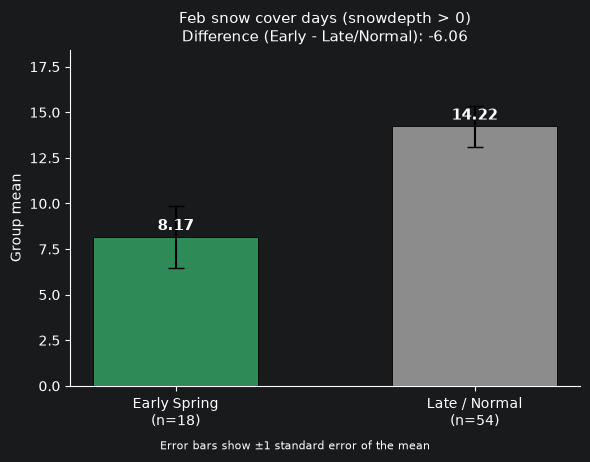

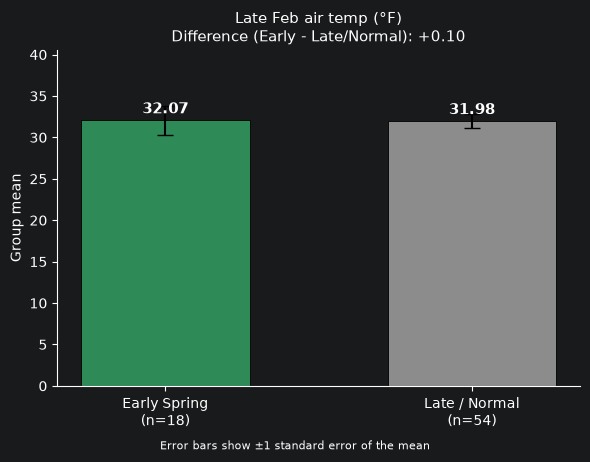

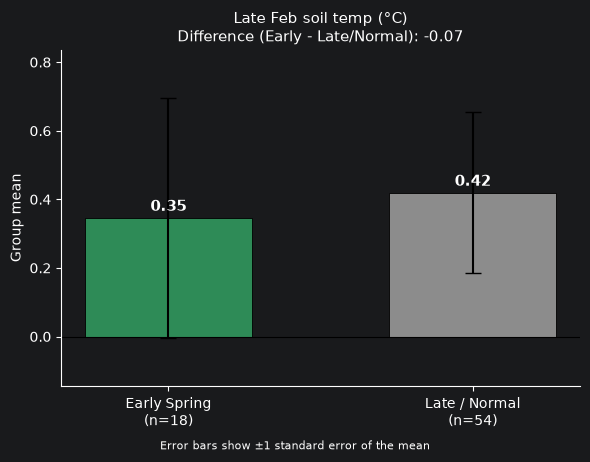

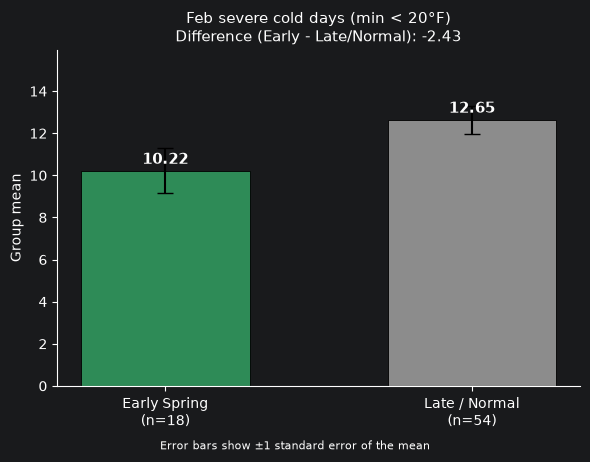

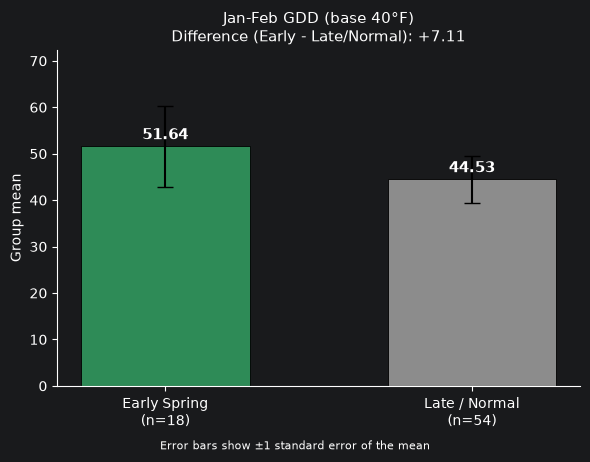

In [5]:
# Plotting the feature differences between Early Spring and Late/Normal years
FEATURE_NAMES = {
    "snow_days": "Feb snow cover days (snowdepth > 0)",
    "air_feb_late": "Late Feb air temp (°F)",
    "soil_feb_late": "Late Feb soil temp (°C)",
    "cold_days": "Feb severe cold days (min < 20°F)",
    "gdd": "Jan-Feb GDD (base 40°F)",
}
GROUPS = ["Early Spring", "Late / Normal"]
COLORS = {"Early Spring": "#2e8b57", "Late / Normal": "#8c8c8c"}

grouped = yearly.groupby("group")[list(FEATURE_NAMES)]
means = grouped.mean().loc[GROUPS]
sems = grouped.sem().loc[GROUPS]
counts = yearly["group"].value_counts()


def plot_feature(col, label):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    bars = ax.bar(
        GROUPS,
        means[col],
        yerr=sems[col],
        capsize=6,
        color=[COLORS[g] for g in GROUPS],
        edgecolor="black",
        linewidth=0.6,
        width=0.55,
    )

    # Label each bar with its mean
    for bar, g in zip(bars, GROUPS):
        value = means.loc[g, col]
        offset = 5 if value >= 0 else -14
        ax.annotate(
            f"{value:.2f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            fontweight="bold",
        )

    diff = means.loc["Early Spring", col] - means.loc["Late / Normal", col]
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{label}\nDifference (Early - Late/Normal): {diff:+.2f}", fontsize=11)
    ax.set_ylabel("Group mean")
    ax.set_xticks(range(len(GROUPS)))
    ax.set_xticklabels(
        [f"Early Spring\n(n={counts['Early Spring']})", f"Late / Normal\n(n={counts['Late / Normal']})"]
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(y=0.2)
    fig.text(0.5, -0.01, "Error bars show ±1 standard error of the mean", ha="center", fontsize=8)
    plt.tight_layout()
    plt.show()


for col, label in FEATURE_NAMES.items():
    plot_feature(col, label)

By separating the years into "Early Spring" and "Late / Normal" groups, we can observe the average values of the computed features for each group. The difference between the two groups is also calculated to highlight the features that may be indicative of early spring onset. The counts of each group are printed, along with the summary statistics for each feature, providing insights into how these features vary between early spring and late/normal years.

In particular, we can see that early spring years tend to have fewer snow cover days, higher late February air and soil temperatures, fewer severe cold days, and higher growing degree days (GDD) compared to late/normal years. These differences suggest that these features may be useful for predicting early spring onset.

/var/folders/1d/h583rbfj6cx29980b7ysz3000000gp/T/ipykernel_87385/2621619368.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


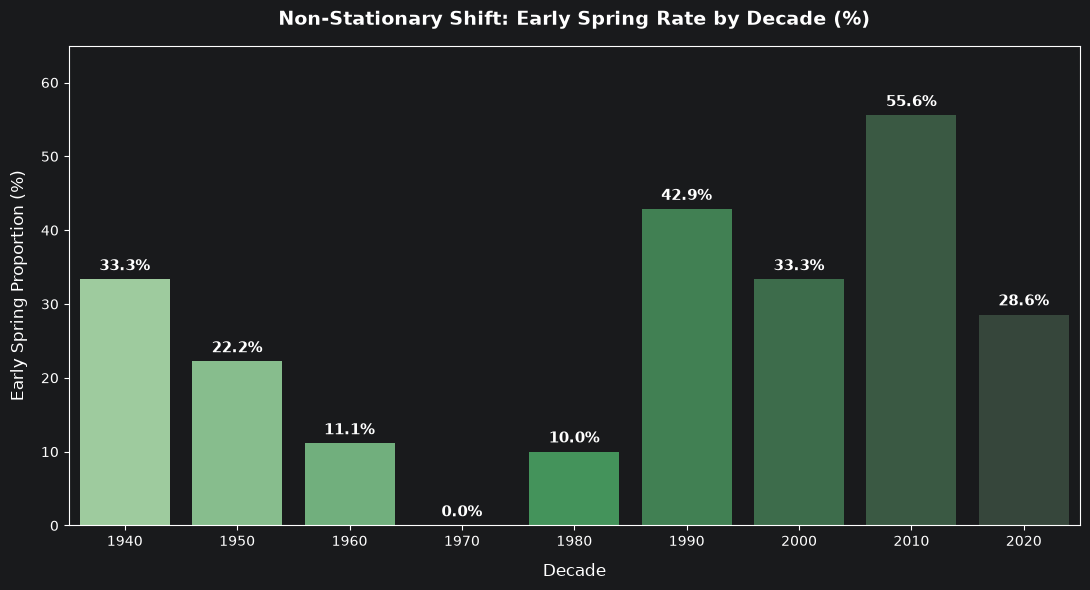

In [6]:
# 1. Load labels dataset
labels = pd.read_csv("early_spring.csv")

# 2. Compute decadal proportions
labels["decade"] = (labels["year"] // 10) * 10
decade_stats = (
    labels.groupby("decade")["early_spring"]
    .agg(["count", "sum"])
    .reset_index()
)
decade_stats["rate"] = (decade_stats["sum"] / decade_stats["count"]) * 100

# 3. Create full-size standalone figure
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=decade_stats,
    x="decade",
    y="rate",
    palette="Greens_d"
)

# 4. Chart titles and axis formatting
plt.title(
    "Non-Stationary Shift: Early Spring Rate by Decade (%)",
    fontsize=14,
    fontweight="bold",
    pad=15
)
plt.xlabel("Decade", fontsize=12, labelpad=10)
plt.ylabel("Early Spring Proportion (%)", fontsize=12, labelpad=10)
plt.ylim(0, 65)

# 5. Annotate exact percentage values on top of each bar
for p in ax.patches:
  height = p.get_height()
  ax.annotate(
      f"{height:.1f}%",
      (p.get_x() + p.get_width() / 2.0, height),
      ha="center",
      va="bottom",
      fontsize=11,
      fontweight="bold",
      xytext=(0, 4),
      textcoords="offset points",
  )

plt.tight_layout()
plt.show()

Something fascinating to note is that the proportion of early spring years has increased over time, particularly starting from that big jump from the 1980s to the 1990s. This suggests a non-stationary shift in the climate, with more frequent early springs occurring in recent decades. The bar chart visualizes this trend, showing the percentage of early spring years for each decade, highlighting the increasing frequency of early spring events over time.

An extremely important outlier to note is that in 1970, there were 0 early spring years, which is a significant deviation from the overall trend. This anomaly may warrant further investigation to understand the underlying causes, such as specific weather patterns or climatic events that occurred during that year.

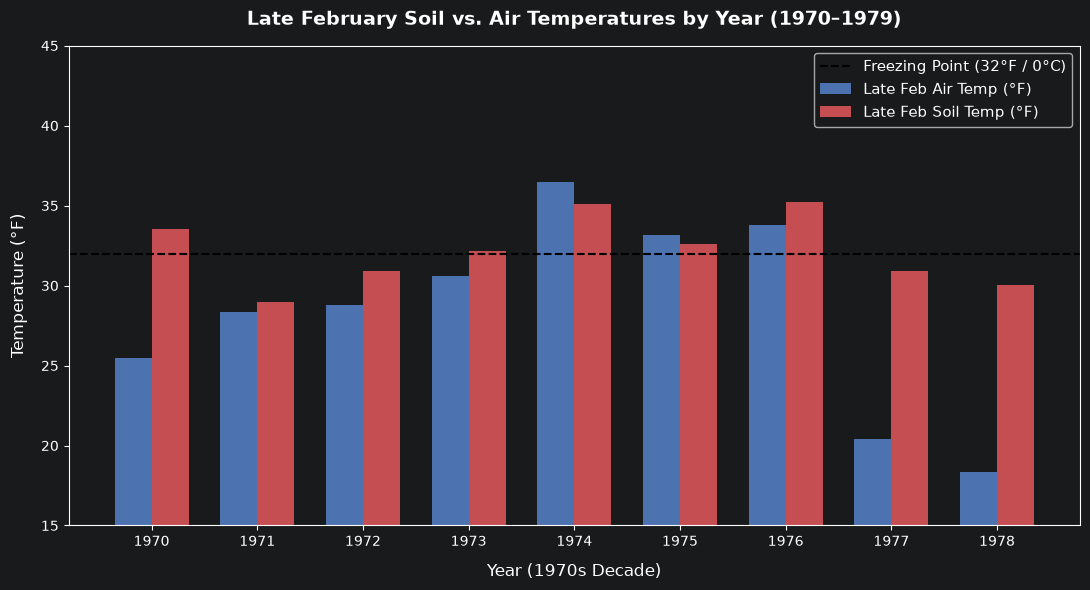

In [7]:
weather = pd.read_csv("weather.csv", parse_dates=["date"])

# Clean numerical weather columns (T = trace -> 0, M = missing -> NaN)
numeric_cols = [
    "max_temp",
    "min_temp",
    "avg_temp",
    "precipitation",
    "snowfall",
    "snowdepth",
]
for col in numeric_cols:
  weather[col] = pd.to_numeric(
      weather[col].astype(str).str.strip().replace({"T": "0"}),
      errors="coerce",
  )

weather["avg_temp"] = weather["avg_temp"].fillna(
    (weather["max_temp"] + weather["min_temp"]) / 2
)

# Merge daily records prior to March 1 cutoff
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].copy()
daily["year"] = daily["date"].dt.year
daily["mean_soil_temp_f"] = daily["mean_soil_temp"] * 1.8 + 32.0

# Filter 1970s decade late February observations (Feb 15 - Feb 28/29)
daily_1970s = daily[(daily["year"] >= 1970) & (daily["year"] <= 1979)]
feb_late_1970s = daily_1970s[daily_1970s["date"].dt.day >= 15]
yearly_1970s = (
    feb_late_1970s.groupby("year")[["avg_temp", "mean_soil_temp_f"]]
    .mean()
    .reset_index()
)


plt.figure(figsize=(11, 6))

x_years = yearly_1970s["year"]
width = 0.35

plt.bar(
    x_years - width / 2,
    yearly_1970s["avg_temp"],
    width,
    label="Late Feb Air Temp (°F)",
    color="#4c72b0",
)
plt.bar(
    x_years + width / 2,
    yearly_1970s["mean_soil_temp_f"],
    width,
    label="Late Feb Soil Temp (°F)",
    color="#c44e52",
)
plt.axhline(
    y=32,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Freezing Point (32°F / 0°C)",
)

plt.title(
    "Late February Soil vs. Air Temperatures by Year (1970–1979)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year (1970s Decade)", fontsize=12, labelpad=10)
plt.ylabel("Temperature (°F)", fontsize=12, labelpad=10)
plt.xticks(x_years)
plt.ylim(15, 45)
plt.legend(loc="upper right", frameon=True, fontsize=11)

plt.tight_layout()
plt.show()

The bar chart shows that in some years, the air temperature was above freezing while the soil temperature remained below freezing, indicating that the ground had not yet thawed despite warmer air temperatures. This highlights the importance of considering both air and soil temperatures when assessing early spring onset, as soil temperature is a more direct indicator of ground thawing and plant growth potential.

/var/folders/1d/h583rbfj6cx29980b7ysz3000000gp/T/ipykernel_87385/1085698963.py:24: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  daily["day_of_year"] = daily["date"].dt.dayofyear


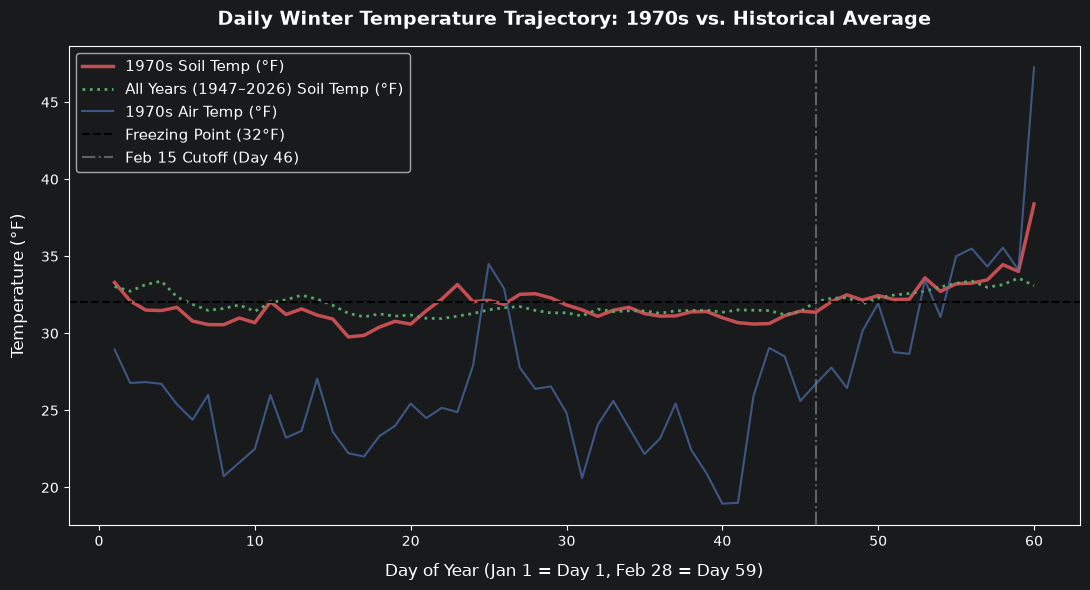

In [8]:
# Clean numerical weather columns (T = trace -> 0, M = missing -> NaN)
numeric_cols = [
    "max_temp",
    "min_temp",
    "avg_temp",
    "precipitation",
    "snowfall",
    "snowdepth",
]
for col in numeric_cols:
  weather[col] = pd.to_numeric(
      weather[col].astype(str).str.strip().replace({"T": "0"}),
      errors="coerce",
  )

weather["avg_temp"] = weather["avg_temp"].fillna(
    (weather["max_temp"] + weather["min_temp"]) / 2
)

# Merge daily records prior to March 1 cutoff
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].copy()
daily["year"] = daily["date"].dt.year
daily["day_of_year"] = daily["date"].dt.dayofyear
daily["mean_soil_temp_f"] = daily["mean_soil_temp"] * 1.8 + 32.0

# Compute daily profile means (Jan 1 to Feb 28/29)
daily_1970s = daily[(daily["year"] >= 1970) & (daily["year"] <= 1979)]
daily_1970s_profile = (
    daily_1970s.groupby("day_of_year")[["avg_temp", "mean_soil_temp_f"]]
    .mean()
    .reset_index()
)
daily_all_profile = (
    daily.groupby("day_of_year")[["avg_temp", "mean_soil_temp_f"]]
    .mean()
    .reset_index()
)

plt.figure(figsize=(11, 6))

plt.plot(
    daily_1970s_profile["day_of_year"],
    daily_1970s_profile["mean_soil_temp_f"],
    label="1970s Soil Temp (°F)",
    color="#c44e52",
    linewidth=2.5,
)
plt.plot(
    daily_all_profile["day_of_year"],
    daily_all_profile["mean_soil_temp_f"],
    label="All Years (1947–2026) Soil Temp (°F)",
    color="#55a868",
    linestyle=":",
    linewidth=2.0,
)
plt.plot(
    daily_1970s_profile["day_of_year"],
    daily_1970s_profile["avg_temp"],
    label="1970s Air Temp (°F)",
    color="#4c72b0",
    linewidth=1.5,
    alpha=0.7,
)
plt.axhline(
    y=32,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Freezing Point (32°F)",
)
plt.axvline(
    x=46,
    color="gray",
    linestyle="-.",
    alpha=0.7,
    label="Feb 15 Cutoff (Day 46)",
)

plt.title(
    "Daily Winter Temperature Trajectory: 1970s vs. Historical Average",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel(
    "Day of Year (Jan 1 = Day 1, Feb 28 = Day 59)", fontsize=12, labelpad=10
)
plt.ylabel("Temperature (°F)", fontsize=12, labelpad=10)
plt.legend(loc="upper left", frameon=True, fontsize=11)

plt.tight_layout()
plt.show()

Seeing the daily temperature trajectories for the 1970s compared to the historical average provides insight into how the winter temperatures varied during that decade. The soil temperature remains below freezing for a longer period in the 1970s, while the air temperature shows more fluctuation. This reinforces the idea that soil temperature is a critical factor in determining early spring onset, as it directly affects the thawing of the ground and subsequent plant growth. Soil will have to be an important factor when determining the onset of early spring, as it is a more direct indicator of the conditions necessary for plant growth and development, while air temperature will assist in that, but not determine it on its own.

In [9]:
phil = pd.read_csv("phil_pred.csv")
m = labels.merge(phil, on="year")
m["correct"] = m["early_spring"].astype(int) == m["prediction"].astype(int)

print(f"Phil accuracy: {m['correct'].mean():.1%}  (n={len(m)})")
print(f"'Never early' baseline accuracy: {1 - m['early_spring'].mean():.1%}")
print()
print(pd.crosstab(m["early_spring"], m["prediction"],
                  rownames=["Actual early"], colnames=["Phil says early"]))

Phil accuracy: 69.4%  (n=72)
'Never early' baseline accuracy: 75.0%

Phil says early  False  True 
Actual early                 
False               45      9
True                13      5


The accuracy of Phil's predictions is calculated by comparing his predictions to the actual early spring labels. The overall accuracy is printed, along with the baseline accuracy of always predicting "never early." Additionally, a confusion matrix is displayed to show the counts of true positives, false positives, true negatives, and false negatives for Phil's predictions. This provides insight into how well Phil's predictions align with the actual early spring occurrences and highlights any potential biases or inaccuracies in his forecasting.

In [10]:
# Impute missing daily avg temp with min/max midpoint

weather["avg_temp"] = weather["avg_temp"].fillna((weather["max_temp"] + weather["min_temp"]) / 2)

# Merge daily records before March 1
daily = soil.merge(weather, on="date", how="outer").sort_values("date")
daily = daily[daily["date"].dt.month < 3].assign(year=lambda d: d["date"].dt.year)

# Extract core yearly features
def extract_key_features(group: pd.DataFrame) -> pd.Series:
    feb = group[group["date"].dt.month == 2]
    feb_late = feb[feb["date"].dt.day >= 15]
    return pd.Series({
        "snow_days": (feb["snowdepth"] > 0).sum(),
        "cold_days": (feb["min_temp"] < 20.0).sum(),
        "gdd": np.maximum(0, group["avg_temp"] - 40.0).sum(),
        "air_feb_late": feb_late["avg_temp"].mean(),
        "soil_feb_late": feb_late["mean_soil_temp"].mean(),
        "soil_moisture": feb["mean_soil_moisture"].mean(),
    })

yearly = daily.groupby("year").apply(extract_key_features).reset_index().merge(labels, on="year")
yearly["early_spring"] = yearly["early_spring"].astype(int)

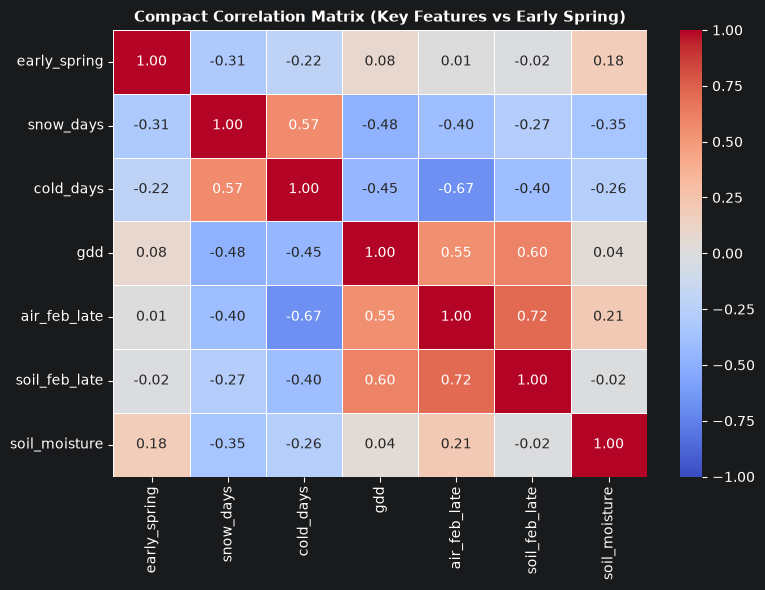

In [11]:
# Define compact feature set
compact_cols = ["early_spring", "snow_days", "cold_days", "gdd", "air_feb_late", "soil_feb_late", "soil_moisture"]
corr_small = yearly[compact_cols].corr()

# Plot Compact Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_small, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Compact Correlation Matrix (Key Features vs Early Spring)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

When creating the correlation matrix, we created several additional features to better help us narrow down the most important features for predicting an early spring. This includes:
- `snow_days`: The number of days in February with snow cover (snowdepth > 0).
- `cold_days`: The number of days in February with minimum temperature below 20°F.
- `gdd`: The cumulative growing degree days (GDD) for January and February, calculated as the sum of (avg_temp - 40°F) for each day, with a minimum of 0.
- `air_feb_late`: The mean air temperature for the late February period (Feb 15-28).
- `soil_feb_late`: The mean soil temperature for the late February period (Feb 15-28).
- `soil_moisture`: The mean soil moisture for February.

When initially looking at the matrix, it's hard to find any strong correlations between features and the target variable `early_spring`. However, like previously mentioned, the combination of features may provide more insight into the prediction of early spring onset. For example, while `air_feb_late` and `soil_feb_late` may not show strong individual correlations with `early_spring`, they show strong correlations with each other, and their combined effect along with other features like `snow_days` and `cold_days` could be significant in determining the likelihood of an early spring.

In [18]:
CACHE_DIR = Path("data_cache")
CACHE_DIR.mkdir(exist_ok=True)

ONI_URL = "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt"
AO_URL = "https://www.cpc.ncep.noaa.gov/products/precip/CWlink/daily_ao_index/monthly.ao.index.b50.current.ascii"


def fetch_cached(url: str, filename: str) -> str:
    """Download once into data_cache/, then reuse the local copy."""
    path = CACHE_DIR / filename
    if not path.exists():
        resp = requests.get(url, headers={"User-Agent": "early-spring-class-project/1.0"}, timeout=60)
        resp.raise_for_status()
        path.write_bytes(resp.content)
    return path.read_text()


# Raw indices
oni_raw = pd.read_csv(io.StringIO(fetch_cached(ONI_URL, "oni.ascii.txt")), sep=r"\s+")
oni_raw.columns = ["season", "year", "total", "anom"]
ao_raw = pd.read_csv(
    io.StringIO(fetch_cached(AO_URL, "ao_monthly.ascii")),
    sep=r"\s+", header=None, names=["year", "month", "ao"],
)

# Lookup tables
oni_nov_jan_by_year = oni_raw.loc[oni_raw["season"] == "NDJ"].set_index("year")["anom"]
ao_by_month = ao_raw.set_index(["year", "month"])["ao"]

# Nov-Jan features known before March 1 of each label year.
# Nov and Dec come from the prior year (Y-1); Jan comes from the label year (Y).
labels = pd.read_csv("early_spring.csv")
label_years = labels["year"].tolist()

feat = pd.DataFrame({"year": label_years})
feat["oni_nov_jan"] = [oni_nov_jan_by_year.get(y - 1, np.nan) for y in label_years]
feat["ao_nov"] = [ao_by_month.get((y - 1, 11), np.nan) for y in label_years]
feat["ao_dec"] = [ao_by_month.get((y - 1, 12), np.nan) for y in label_years]
feat["ao_jan"] = [ao_by_month.get((y, 1), np.nan) for y in label_years]
feat["ao_nov_jan_mean"] = feat[["ao_nov", "ao_dec", "ao_jan"]].mean(axis=1, skipna=False)

idx = feat.merge(labels, on="year")
idx["early_spring"] = idx["early_spring"].astype(int)
idx["group"] = np.where(idx["early_spring"] == 1, "Early Spring", "Late / Normal")

INDEX_COLS = [c for c in feat.columns if c != "year"]
print(f"Years: {len(idx)}  |  Early: {idx['early_spring'].sum()}  |  Late/Normal: {(1 - idx['early_spring']).sum()}\n")
idx.info()

Years: 72  |  Early: 18  |  Late/Normal: 54

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year             72 non-null     int64  
 1   oni_nov_jan      68 non-null     float64
 2   ao_nov           68 non-null     float64
 3   ao_dec           68 non-null     float64
 4   ao_jan           69 non-null     float64
 5   ao_nov_jan_mean  68 non-null     float64
 6   early_spring     72 non-null     int64  
 7   group            72 non-null     str    
dtypes: float64(5), int64(2), str(1)
memory usage: 4.6 KB


The index dataset contains climate indices that may influence early spring occurrences. The dataset includes the Oceanic Niño Index (ONI) for the November-January period and the Arctic Oscillation (AO) index for November, December, and January. These indices are known to have potential correlations with early spring events. The dataset is merged with the early spring labels, and the `early_spring` column is converted to an integer type for analysis. The `group` column is created to categorize the years into "Early Spring" and "Late / Normal" groups based on the `early_spring` label.

In [20]:
incomplete = idx[idx[INDEX_COLS].isna().any(axis=1)][["year", "early_spring"] + INDEX_COLS]
print(f"Rows with at least one missing index value: {len(incomplete)}\n")
print(incomplete.to_string(index=False))

Rows with at least one missing index value: 4

 year  early_spring  oni_nov_jan  ao_nov  ao_dec  ao_jan  ao_nov_jan_mean
 1949             1          NaN     NaN     NaN     NaN              NaN
 1948             0          NaN     NaN     NaN     NaN              NaN
 1947             0          NaN     NaN     NaN     NaN              NaN
 1950             0          NaN     NaN     NaN -0.0603              NaN


Interestingly enough, there are a few years with missing index values, which may affect the analysis. The missing values are displayed in the `incomplete` DataFrame, showing the years and their corresponding early spring labels along with the missing index values. This information is crucial for understanding potential gaps in the dataset and how they may impact the overall analysis of early spring occurrences in relation to climate indices.

However, we have some of the missing data in other datasets, like the early spring labels, but we will need to be cautious when interpreting results for these years with incomplete index data.